# Úkol č. 3 - shlukování

  * **Deadline je do 28. 12. 2022, 23:59:59**, pokud odevzdáte úkol do 4. 1. 2023, 23:59:59, budete penalizování -4 body, pozdější odevzdání je bez bodu.
  * V rámci tohoto úkolu se musíte vypořádat s problematikou shlukování.
    
> **Úkoly jsou zadány tak, aby Vám daly prostor pro invenci. Vymyslet _jak přesně_ budete úkol řešit, je důležitou součástí zadání a originalita či nápaditost bude také hodnocena!**

Využívejte buňky typu `Markdown` k vysvětlování Vašeho postupu. Za nepřehlednost budeme strhávat body.

## Zdroj dat

  * Zdrojem dat je soubor `CC GENERAL.csv` (originál zde: https://www.kaggle.com/datasets/arjunbhasin2013/ccdata).
  * Popis datasetu najdete v souboru `data_description.txt`.

## Pokyny k vypracování

**Body zadání**, za jejichž (poctivé) vypracování získáte **16 bodů**:
  * Proveďte základní průzkum dat a svá pozorování diskutujte. Na jeho základě adekvátně reagujte na problematické věci v datech (chybějící hodnoty, atd.) a vysvětlete motivaci k provedeným krokům.
  * Vytvořte **vlastní implementaci** algoritmu KMeans.
  * Pomocí této vlastní implementace proveďte shlukování.
  * Zopakujte shlukování s implementací `sklearn.cluster.KMeans`. Pokuste se sladit hyperparametry tak, abyste dostali stejné výsledky. Pokud se Vám to nepovede, diskutujte proč.
  * Pokuste se odhadnout vhodný počet shluků (např. metodou lokte).
  * Proveďte také aglomerativní hierarchické shlukování (použijte existující implementaci) a nakreslete dendrogram (resp. alespoň jeho vhodnou horní část).
  * Zopakujte předchozí kroky a při tom experimentujte s různými hodnotami hyperparametrů a také se standardizací/normalizací dat.
    * Kvalitu vytvořených shluků můžete analyzovat pomocí metody Silhouette (https://en.wikipedia.org/wiki/Silhouette_(clustering)).
  * Cílem je vybrat shlukování, které Vám přijde nejlepší (můžete přihlédnout k následujícímu bodu). Popište, proč jste ho vybrali.
  * Na tomto vybraném shlukování se pokuste interpretovat výsledné shluky.
    * Snažte se identifikovat a popsat typy uživatelů kreditních karet podle Vámi zvolených vybraných kritérií. Můžete přitom koukat například na BALANCE, PURCHASES, CASH_ADVANCE, PAYMENTS, atd.
  

## Poznámky k odevzdání

  * Řiďte se pokyny ze stránky https://courses.fit.cvut.cz/BI-ML1/homeworks/index.html.
  * Opravující Vám ve výjimečných případech může umožnit úkol dodělat či opravit a získat tak další body. První verze je ale stěžejní a má hlavní vliv na hodnocení.

In [1]:
### odtud už je to Vaše

<b>Start of project</b>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics, datasets
from scipy.cluster.hierarchy import *
import random


from scipy.cluster.hierarchy import linkage
from scipy.cluster.hierarchy import fcluster
from scipy.cluster.hierarchy import dendrogram
from sklearn.metrics import silhouette_score

#dendogram
import sys
sys.setrecursionlimit(10000)

Import the data and take a quick look at what values are we using and which are missing

In [3]:
df = pd.read_csv("CC GENERAL.csv")
display(df.head())
display(df.shape)
display(df.isnull().sum())
df.dtypes

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


(8950, 18)

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

CUST_ID                              object
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENTS                            float64
MINIMUM_PAYMENTS                    float64
PRC_FULL_PAYMENT                    float64
TENURE                                int64
dtype: object

All of the data columns use numerical values, which will be easy to work with.

There are only a few <b>missing values</b> and based off of other data it looks like we could fill them with some averaged out values. However there seem to be inconsistecies even in the columns that have data and as most of the values would end up as 0 either way, as they just seem to be unused columns for that specific row, the simplest fix is just to fill everyhting with <b>0s</b>. 

In [4]:
df = df.fillna(0)

In [5]:
display(df.isnull().sum())

CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

Create a <b>dfdata</b> dataframe without the id's and an <b>arraydata</b> array, which will be a simple np array with the same data.


Important note: I am still not sure if the assignment was to run clustering on the whole dataset, choose the best one and interpret created clusters. 
Or if it was to choose some columns and try to create clusters based on some criteria we chose beforehand.
Remarkably it runs quite well even if it's done in the latter way, just uncomment the line which drops all other columns, to choose  different version, obviously the text now won't match the results precisely.

In [6]:
display(df.shape)

#original version
df = df.drop(['CUST_ID'], 1)
dfdata = df

# 2 feature version
# df = df.drop(['CUST_ID', 'BALANCE_FREQUENCY',  'INSTALLMENTS_PURCHASES',
#  'CASH_ADVANCE', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
#  'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX',
#  'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'PURCHASES_FREQUENCY', 'TENURE', 'CREDIT_LIMIT', 'ONEOFF_PURCHASES' ], 1)

# 4 feature version
# df = df.drop(['CUST_ID', 'BALANCE_FREQUENCY',  'INSTALLMENTS_PURCHASES',
#  'CASH_ADVANCE', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
#  'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX',
#  'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'PURCHASES_FREQUENCY', 'TENURE' ], 1)

dfdata = df
display(dfdata.shape)
arraydata = np.array(dfdata)
display(arraydata.shape)

(8950, 18)

(8950, 17)

(8950, 17)

Fucntion for drawing the graph of labeled nodes with account balance on the x-axis and purchases on the y-axis.

Separating card holders by the amount of purchases they make and how much money they have is useful for knowing which people can afford and are likely to buy which kind of product. 
This will be taken into account for determining the ideal clustering.

In [7]:
def BalancePurchasesGraph(classification, df):
    df['cl'] = classification
    df.plot.scatter('BALANCE', 'PURCHASES', c='cl', colormap='gist_rainbow')
    plt.show()

<b>Custom K-Means implementation.</b>

In [8]:
def kmeanspt(df, K, max_iter=100, tolerance = 1e-04):
    
    #convert dataframe to array
    X= df.values
    #create an array storing index labels of for every point
    cluster_indexes =[0]*len(df.index)

    #randomly initialize centers
    centers = X[np.random.choice(np.arange(len(X)), K, replace=False)]
    
    for i in range(max_iter):
        #initialize an empty list for each cluster
        clusters = [[] for i in range(K)]
        
        #assign each point to the closest center
        for i, x in enumerate(X):
            dist = np.linalg.norm(x - centers, axis=1)
            closest_center = np.argmin(dist)
            clusters[closest_center].append(x)
            cluster_indexes[i] = closest_center
        
        #update the centers to the mean of the points in the cluster
        new_centers = np.array([np.mean(cluster, axis=0) for cluster in clusters])
        
        #compute the difference between the old and new centers
        diff = np.abs(centers - new_centers).mean()

        #check for convergence
        if np.allclose(new_centers, centers) or diff < tolerance:
            break

        centers = new_centers
    
    #add cluster labels to dataframe
    df['cluster'] = cluster_indexes
    return df


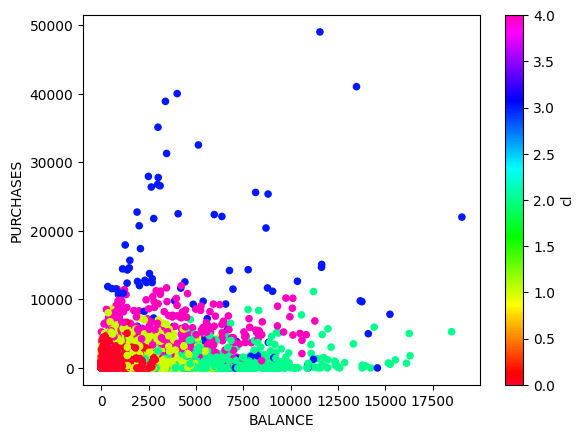

The silhouette score is 0.345


In [9]:
ptresult = kmeanspt(dfdata,5)
BalancePurchasesGraph(ptresult['cluster'], ptresult)
score = silhouette_score(ptresult, ptresult['cluster'])
print(f"The silhouette score is {score:.3f}")

<b>Sklearn K-Means</b>

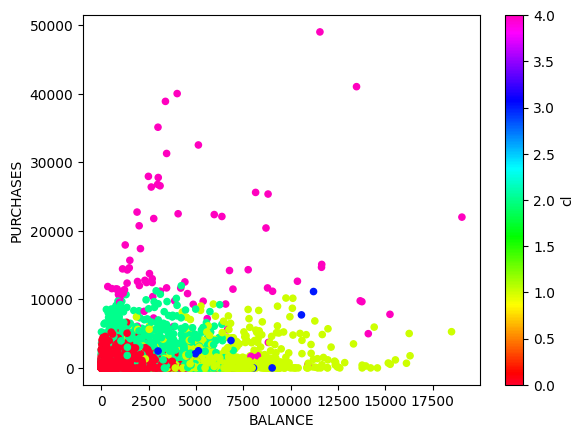

The silhouette score is 0.402


In [10]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters = 5, max_iter =100).fit(dfdata)
BalancePurchasesGraph(kmeans.labels_, dfdata)
score = silhouette_score(dfdata, kmeans.labels_)
print(f"The silhouette score is {score:.3f}")

Both implementations achieve simillar but not exactly the same results.
The biggest difference is probably in the randomized selection of starting points, which can have a big impact on which local minimum will the algorithm find.

I tried to align some parameters such as max_iterations and tolerance with the sklearn implementation but in this case it did not seem to make a significant difference compared to the default settings.


<b>Elbow method</b>

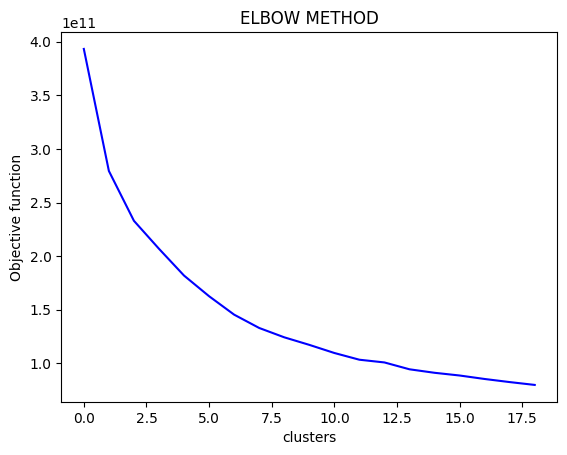

In [11]:
elbow=[]
for i in range(1, 20):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 1)
    kmeans.fit(arraydata)
    elbow.append(kmeans.inertia_)
sns.lineplot(elbow,color='blue')
plt.rcParams.update({'figure.figsize':(10,7.5), 'figure.dpi':100})
plt.title('ELBOW METHOD')
plt.xlabel('clusters')
plt.ylabel('Objective function')
plt.show()

The ideal number of clusters for the original dataset seems to be somewhere around 5.
The drop is not as sharp so it's hard to estimate an exact number.


<b>Silhouette</b>

Function for graphing silhouette scores from 2 to 10 clusters with k-means.
It will be used to compare the individual algorithms and determine where they perform best.
(Higher score is better, clusters fit more in their cluster.)

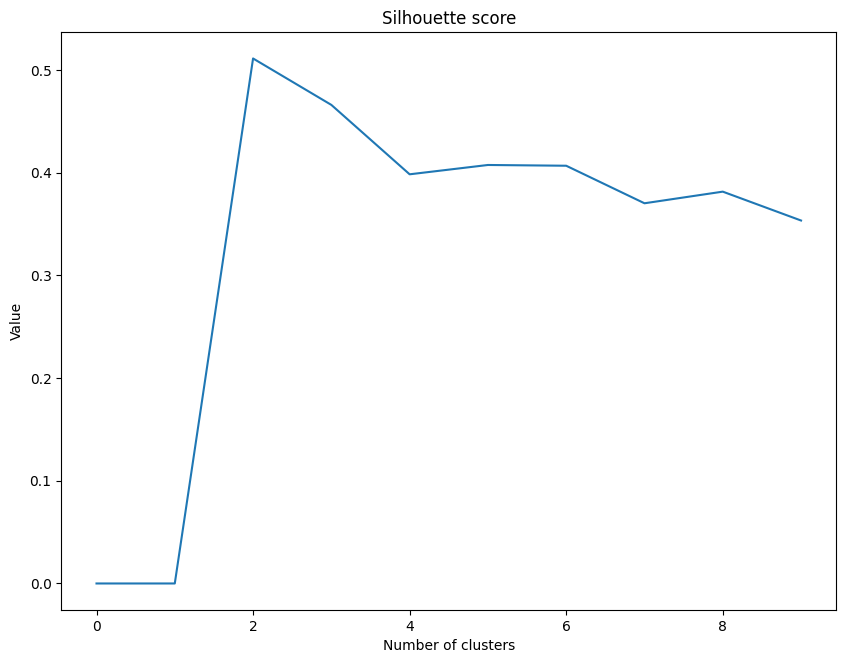

In [12]:
def silhouette_graph(df):
    silhouette_scores=[]
    silhouette_scores.append(0)
    silhouette_scores.append(0)
    for i in range(2, 10):
        kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 101)
        kmeans.fit(df)
        score = silhouette_score(df, kmeans.labels_)
        silhouette_scores.append(score)
    plt.plot (silhouette_scores)
    plt.xlabel("Number of clusters")
    plt.ylabel("Value")
    plt.title("Silhouette score")
    plt.show()

#original dataset
silhouette_graph(arraydata)

<b>Standardization and Normalization</b>

It's unclear if in this case limiting values to the range (0,1) will have a positive impact.

Some numbers such as balance use large figures which skew the results, that said balance is coincidentally one of the most important metrics of our interpretation of the results.

Overall, it should still provide a clearer picture, we will be comparing the results with the silhouette_graph functions where scaling should help.

In [13]:
from sklearn.preprocessing import MinMaxScaler

# Create a MinMaxScaler object
scaler = MinMaxScaler()

dfdata = df
# Fit the scaler to the DataFrame and transform the data
df_normalized = scaler.fit_transform(dfdata)

# Convert the transformed data back into a DataFrame
df_normalized = pd.DataFrame(df_normalized, columns=dfdata.columns)

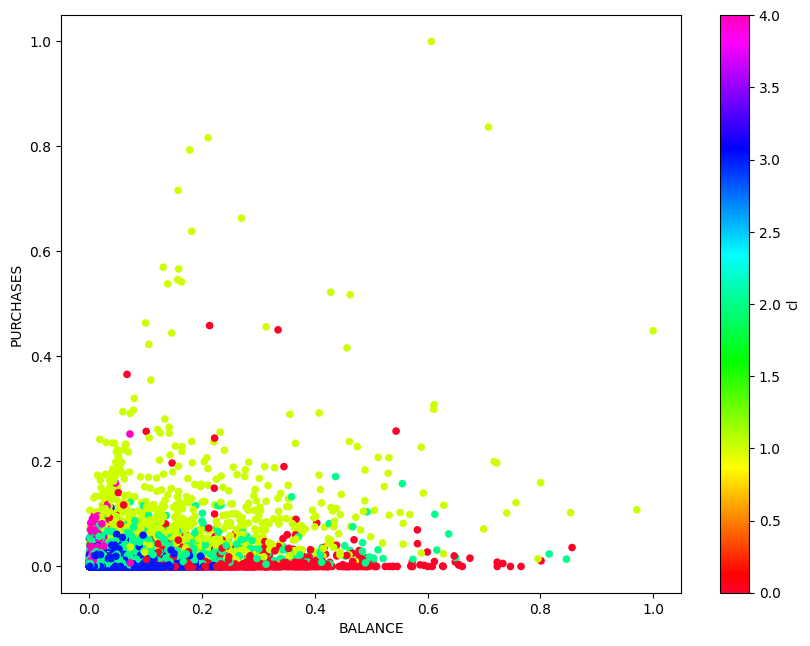

In [14]:
kmeans = KMeans(n_clusters = 5).fit(df_normalized)
BalancePurchasesGraph(kmeans.labels_, df_normalized)

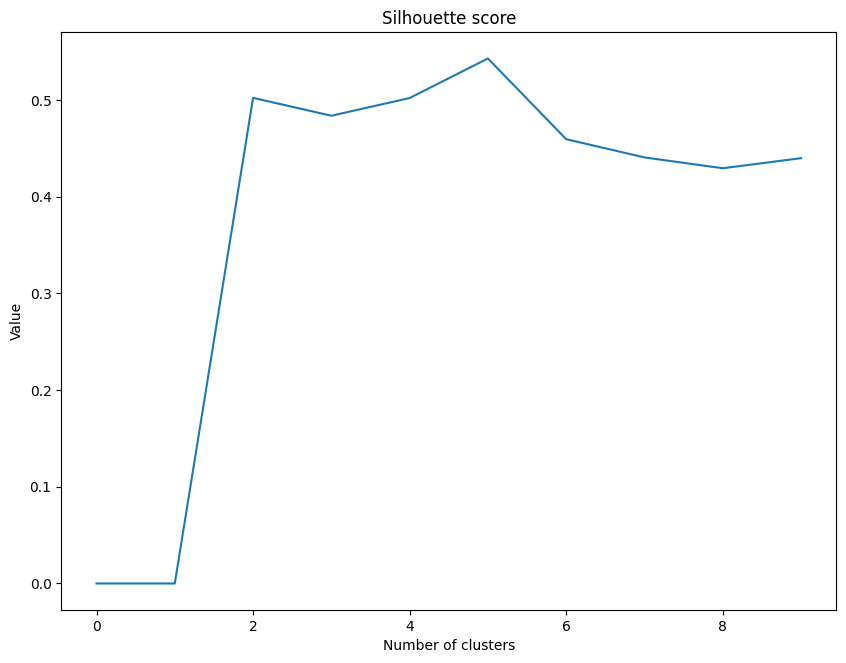

In [15]:
silhouette_graph(df_normalized)

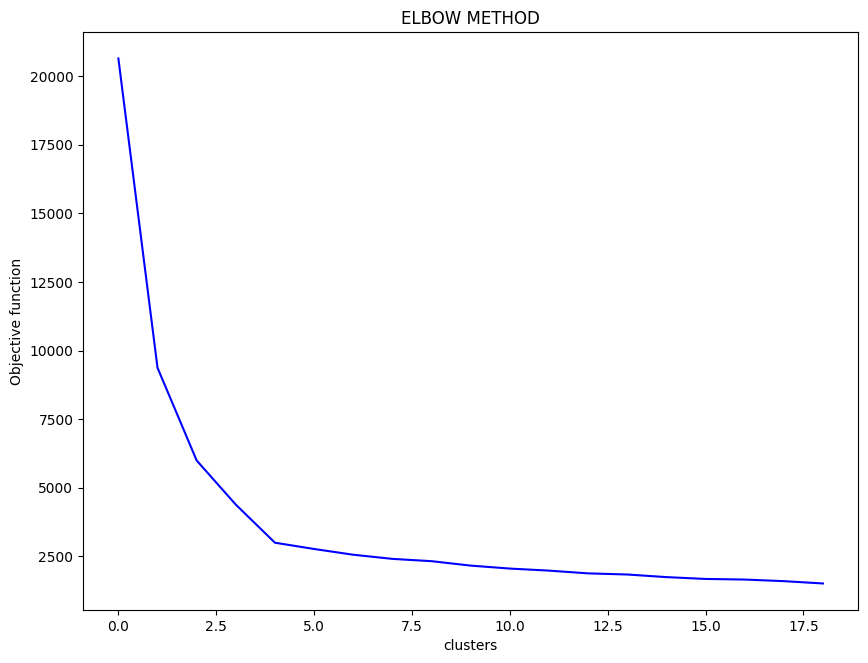

In [16]:
elbow=[]
for i in range(1, 20):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 1)
    kmeans.fit(df_normalized)
    elbow.append(kmeans.inertia_)
sns.lineplot(elbow,color='blue')
plt.rcParams.update({'figure.figsize':(10,7.5), 'figure.dpi':100})
plt.title('ELBOW METHOD')
plt.xlabel('clusters')
plt.ylabel('Objective function')
plt.show()

Normalization has improved the silhouette score and the elbow method produces a sharper curve.

In [17]:
from sklearn.preprocessing import StandardScaler

# Create a StandardScaler object
scaler = StandardScaler()

dfdata = df
# Fit the scaler to the DataFrame and transform the data
df_standardized = scaler.fit_transform(dfdata)

# Convert the transformed data back into a DataFrame
df_standardized = pd.DataFrame(df_standardized, columns=dfdata.columns)

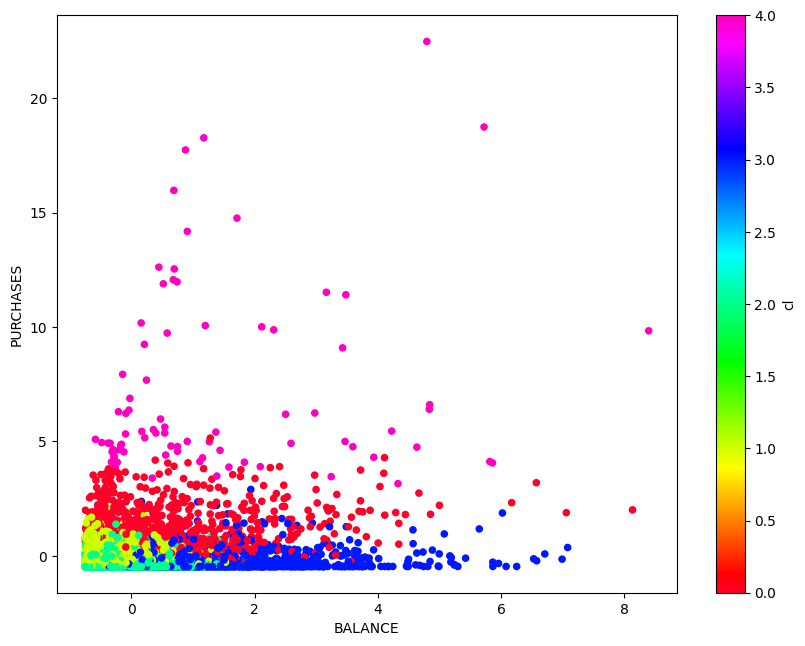

In [18]:
kmeans = KMeans(n_clusters = 5).fit(df_standardized)
BalancePurchasesGraph(kmeans.labels_, df_standardized)

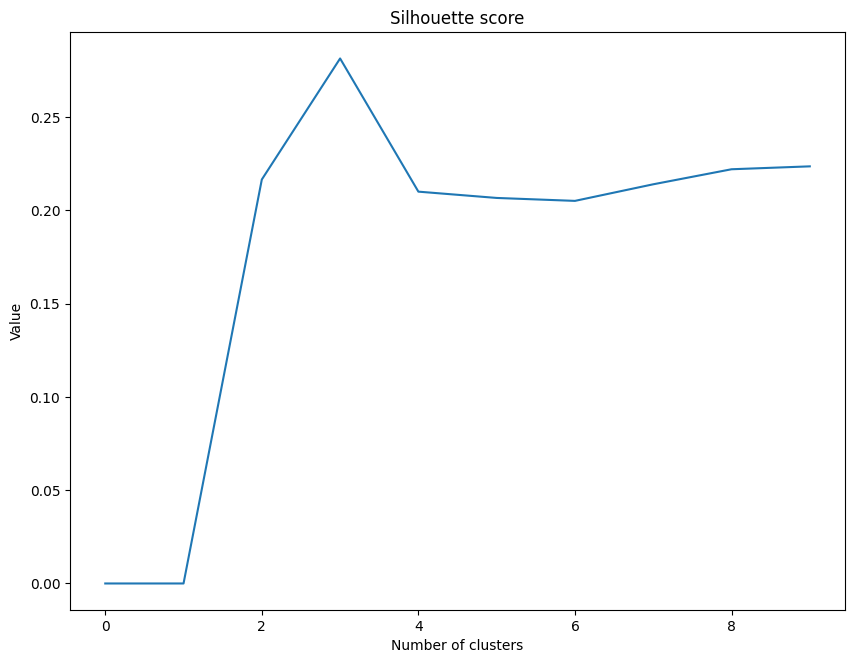

In [19]:
silhouette_graph(df_standardized)

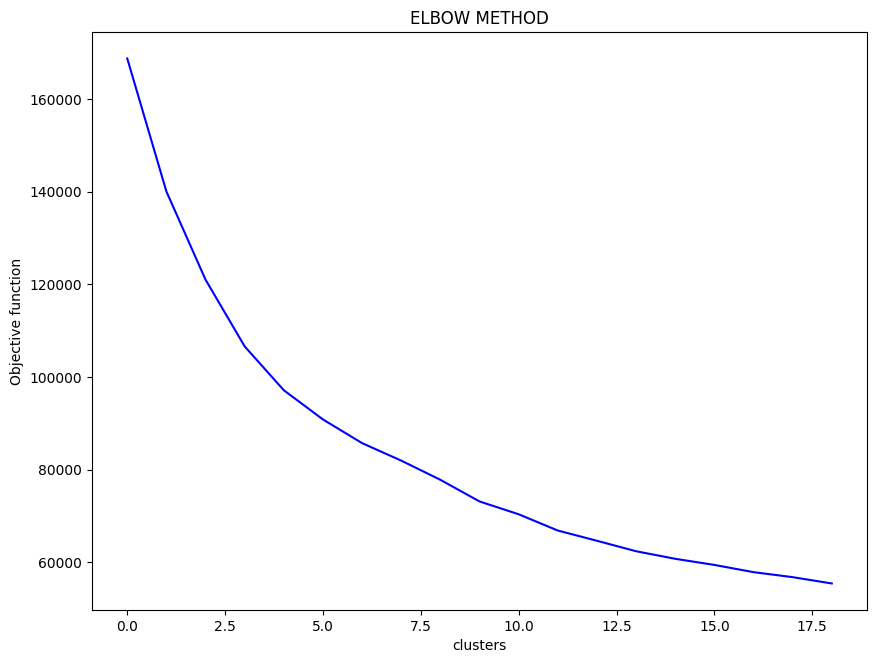

In [20]:
elbow=[]
for i in range(1, 20):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 1)
    kmeans.fit(df_standardized)
    elbow.append(kmeans.inertia_)
sns.lineplot(elbow,color='blue')
plt.rcParams.update({'figure.figsize':(10,7.5), 'figure.dpi':100})
plt.title('ELBOW METHOD')
plt.xlabel('clusters')
plt.ylabel('Objective function')
plt.show()

Standardization did not seem to help this time.

<b>Agglomerative Hierarchical Clustering</b>

Let's try to run the common linkage methods and graph their dendograms.

Method used: ward
The silhouette score is 0.543


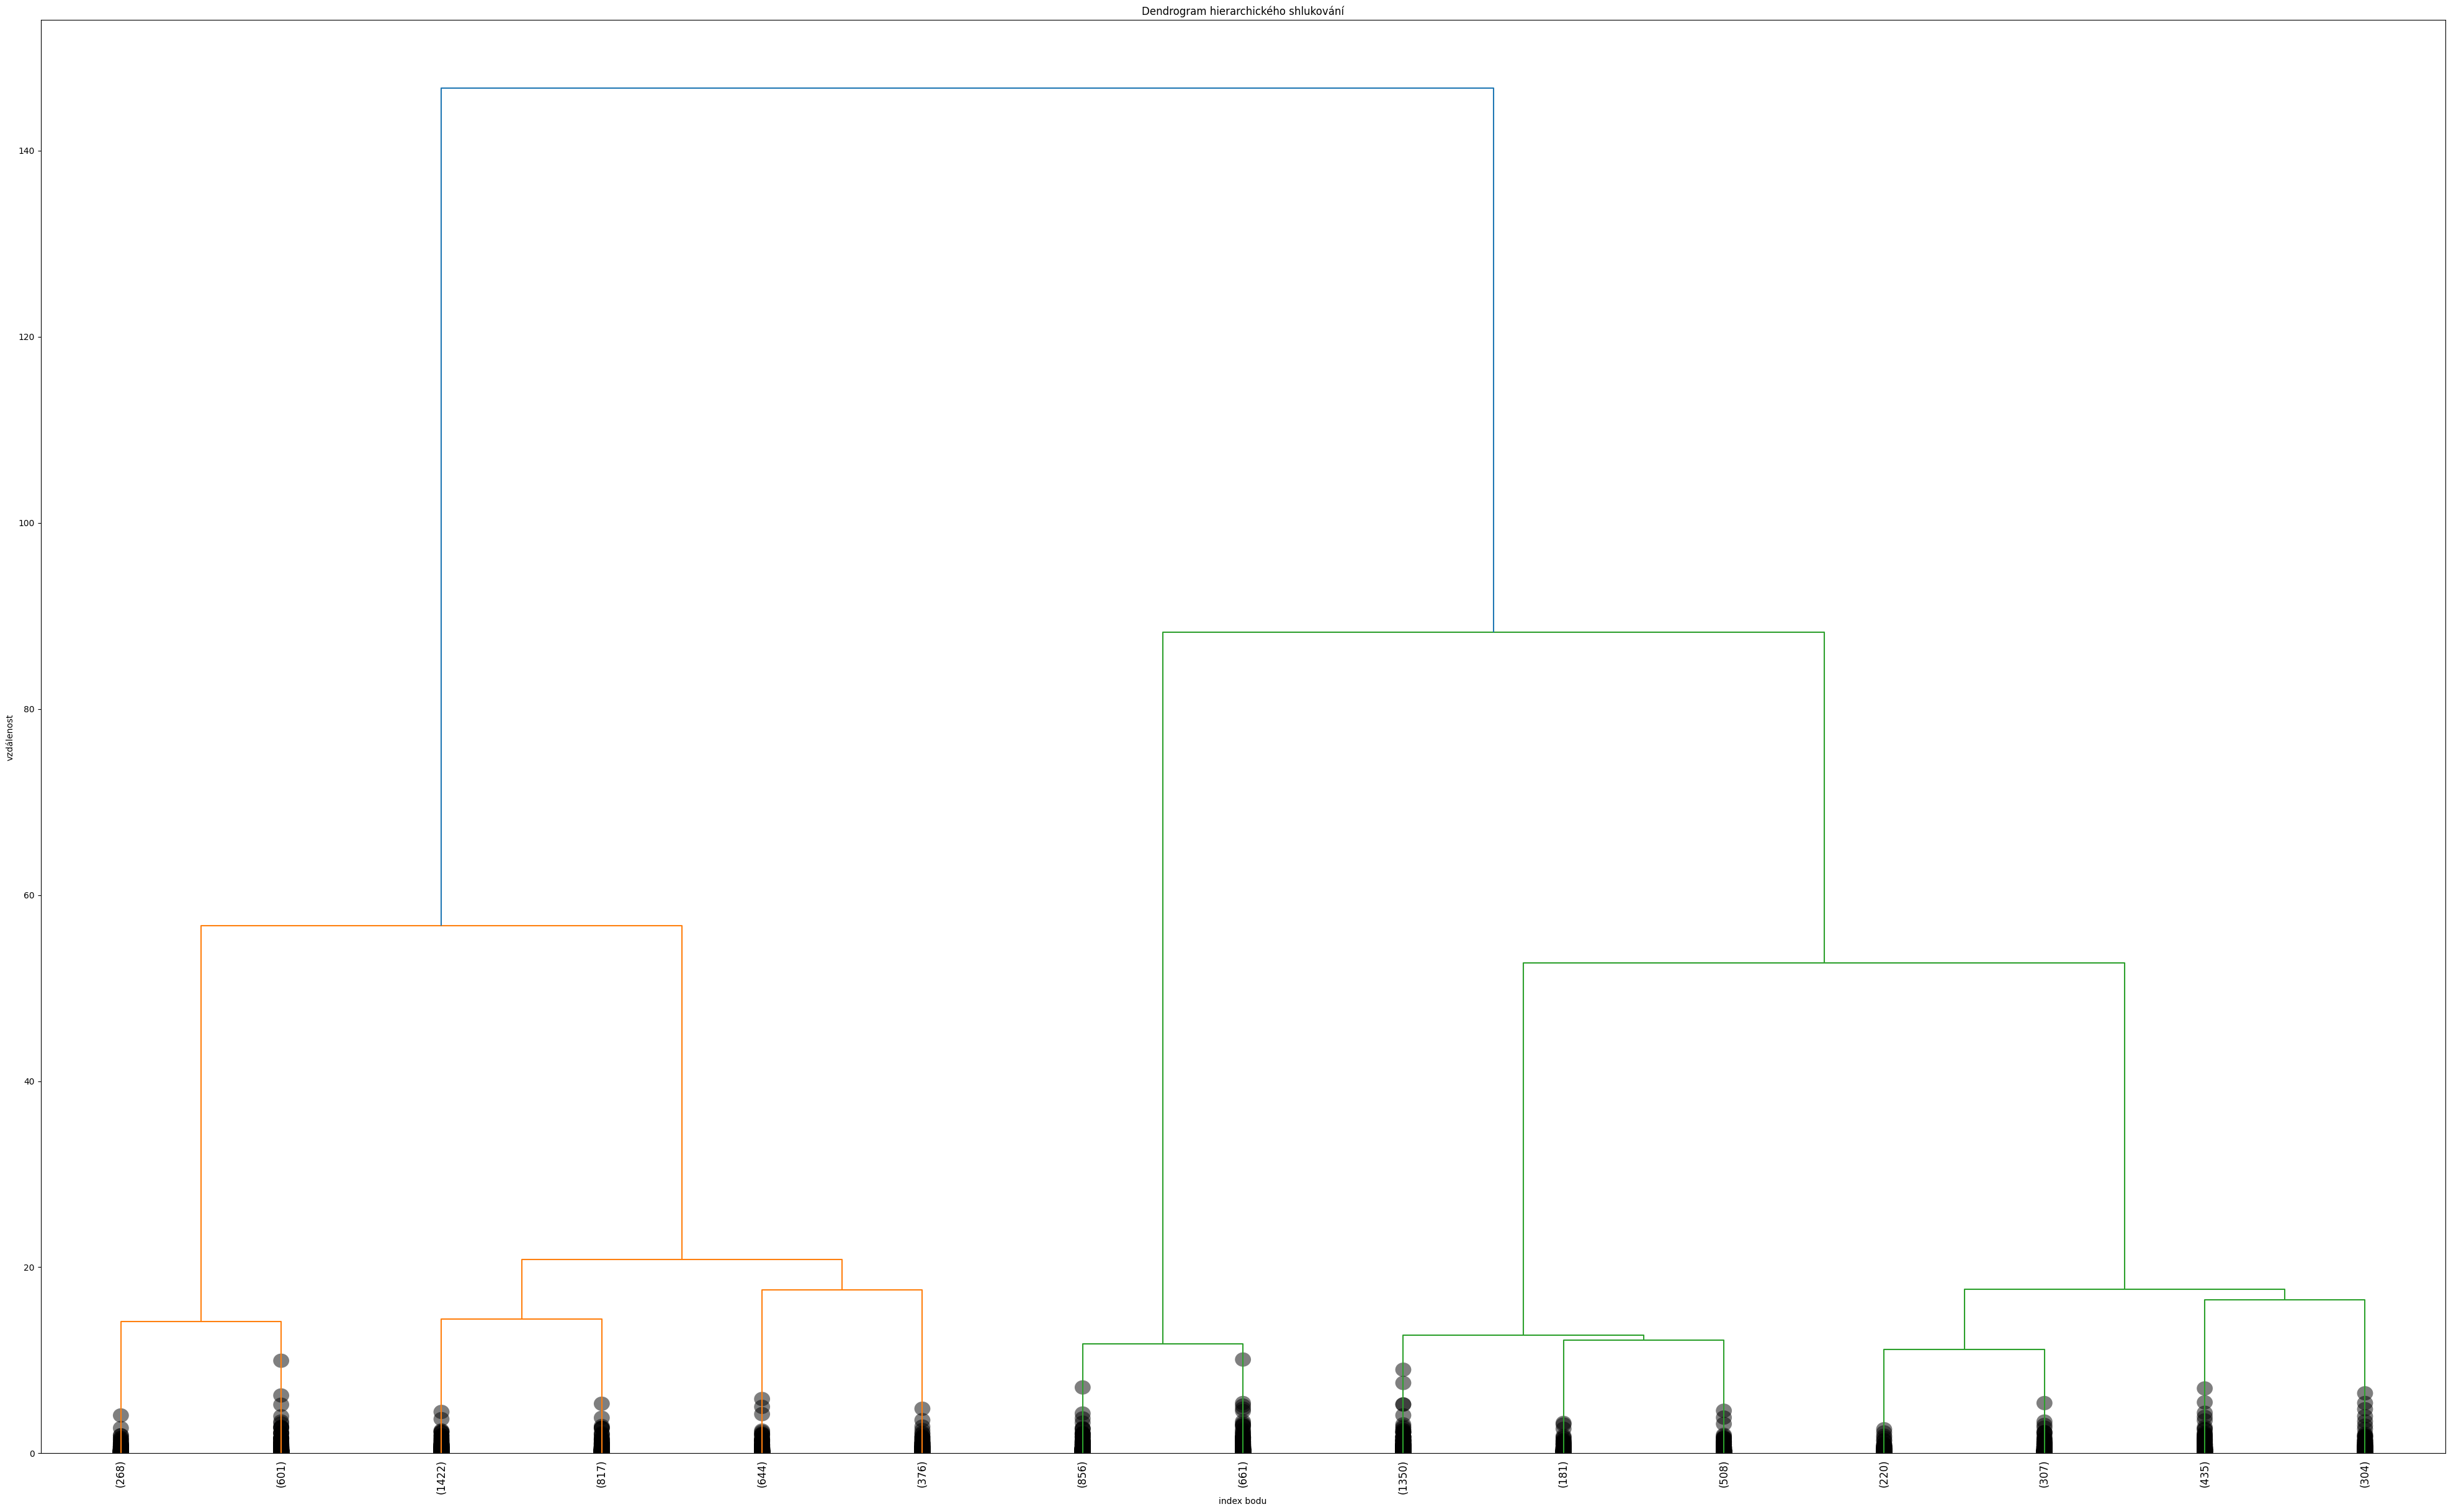

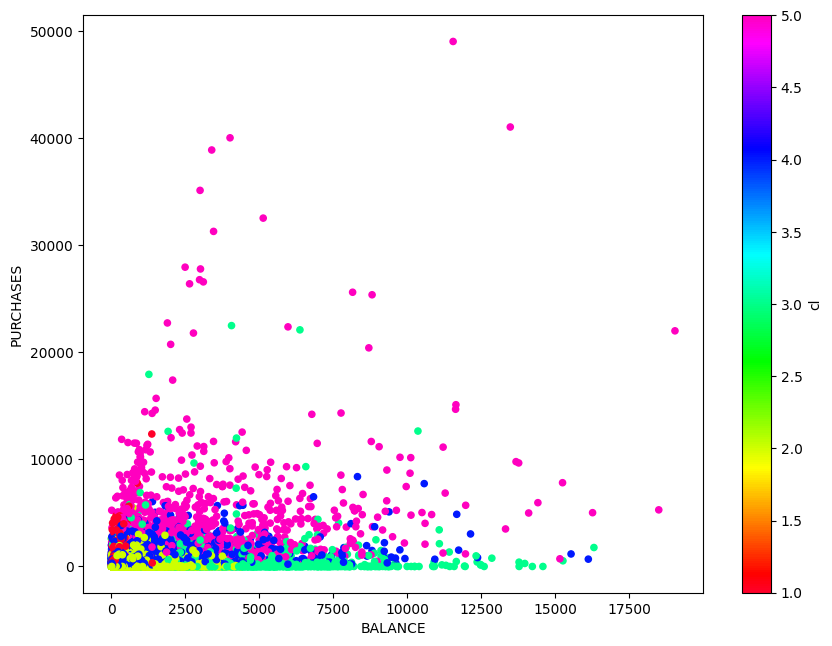

Method used: single
The silhouette score is 0.411


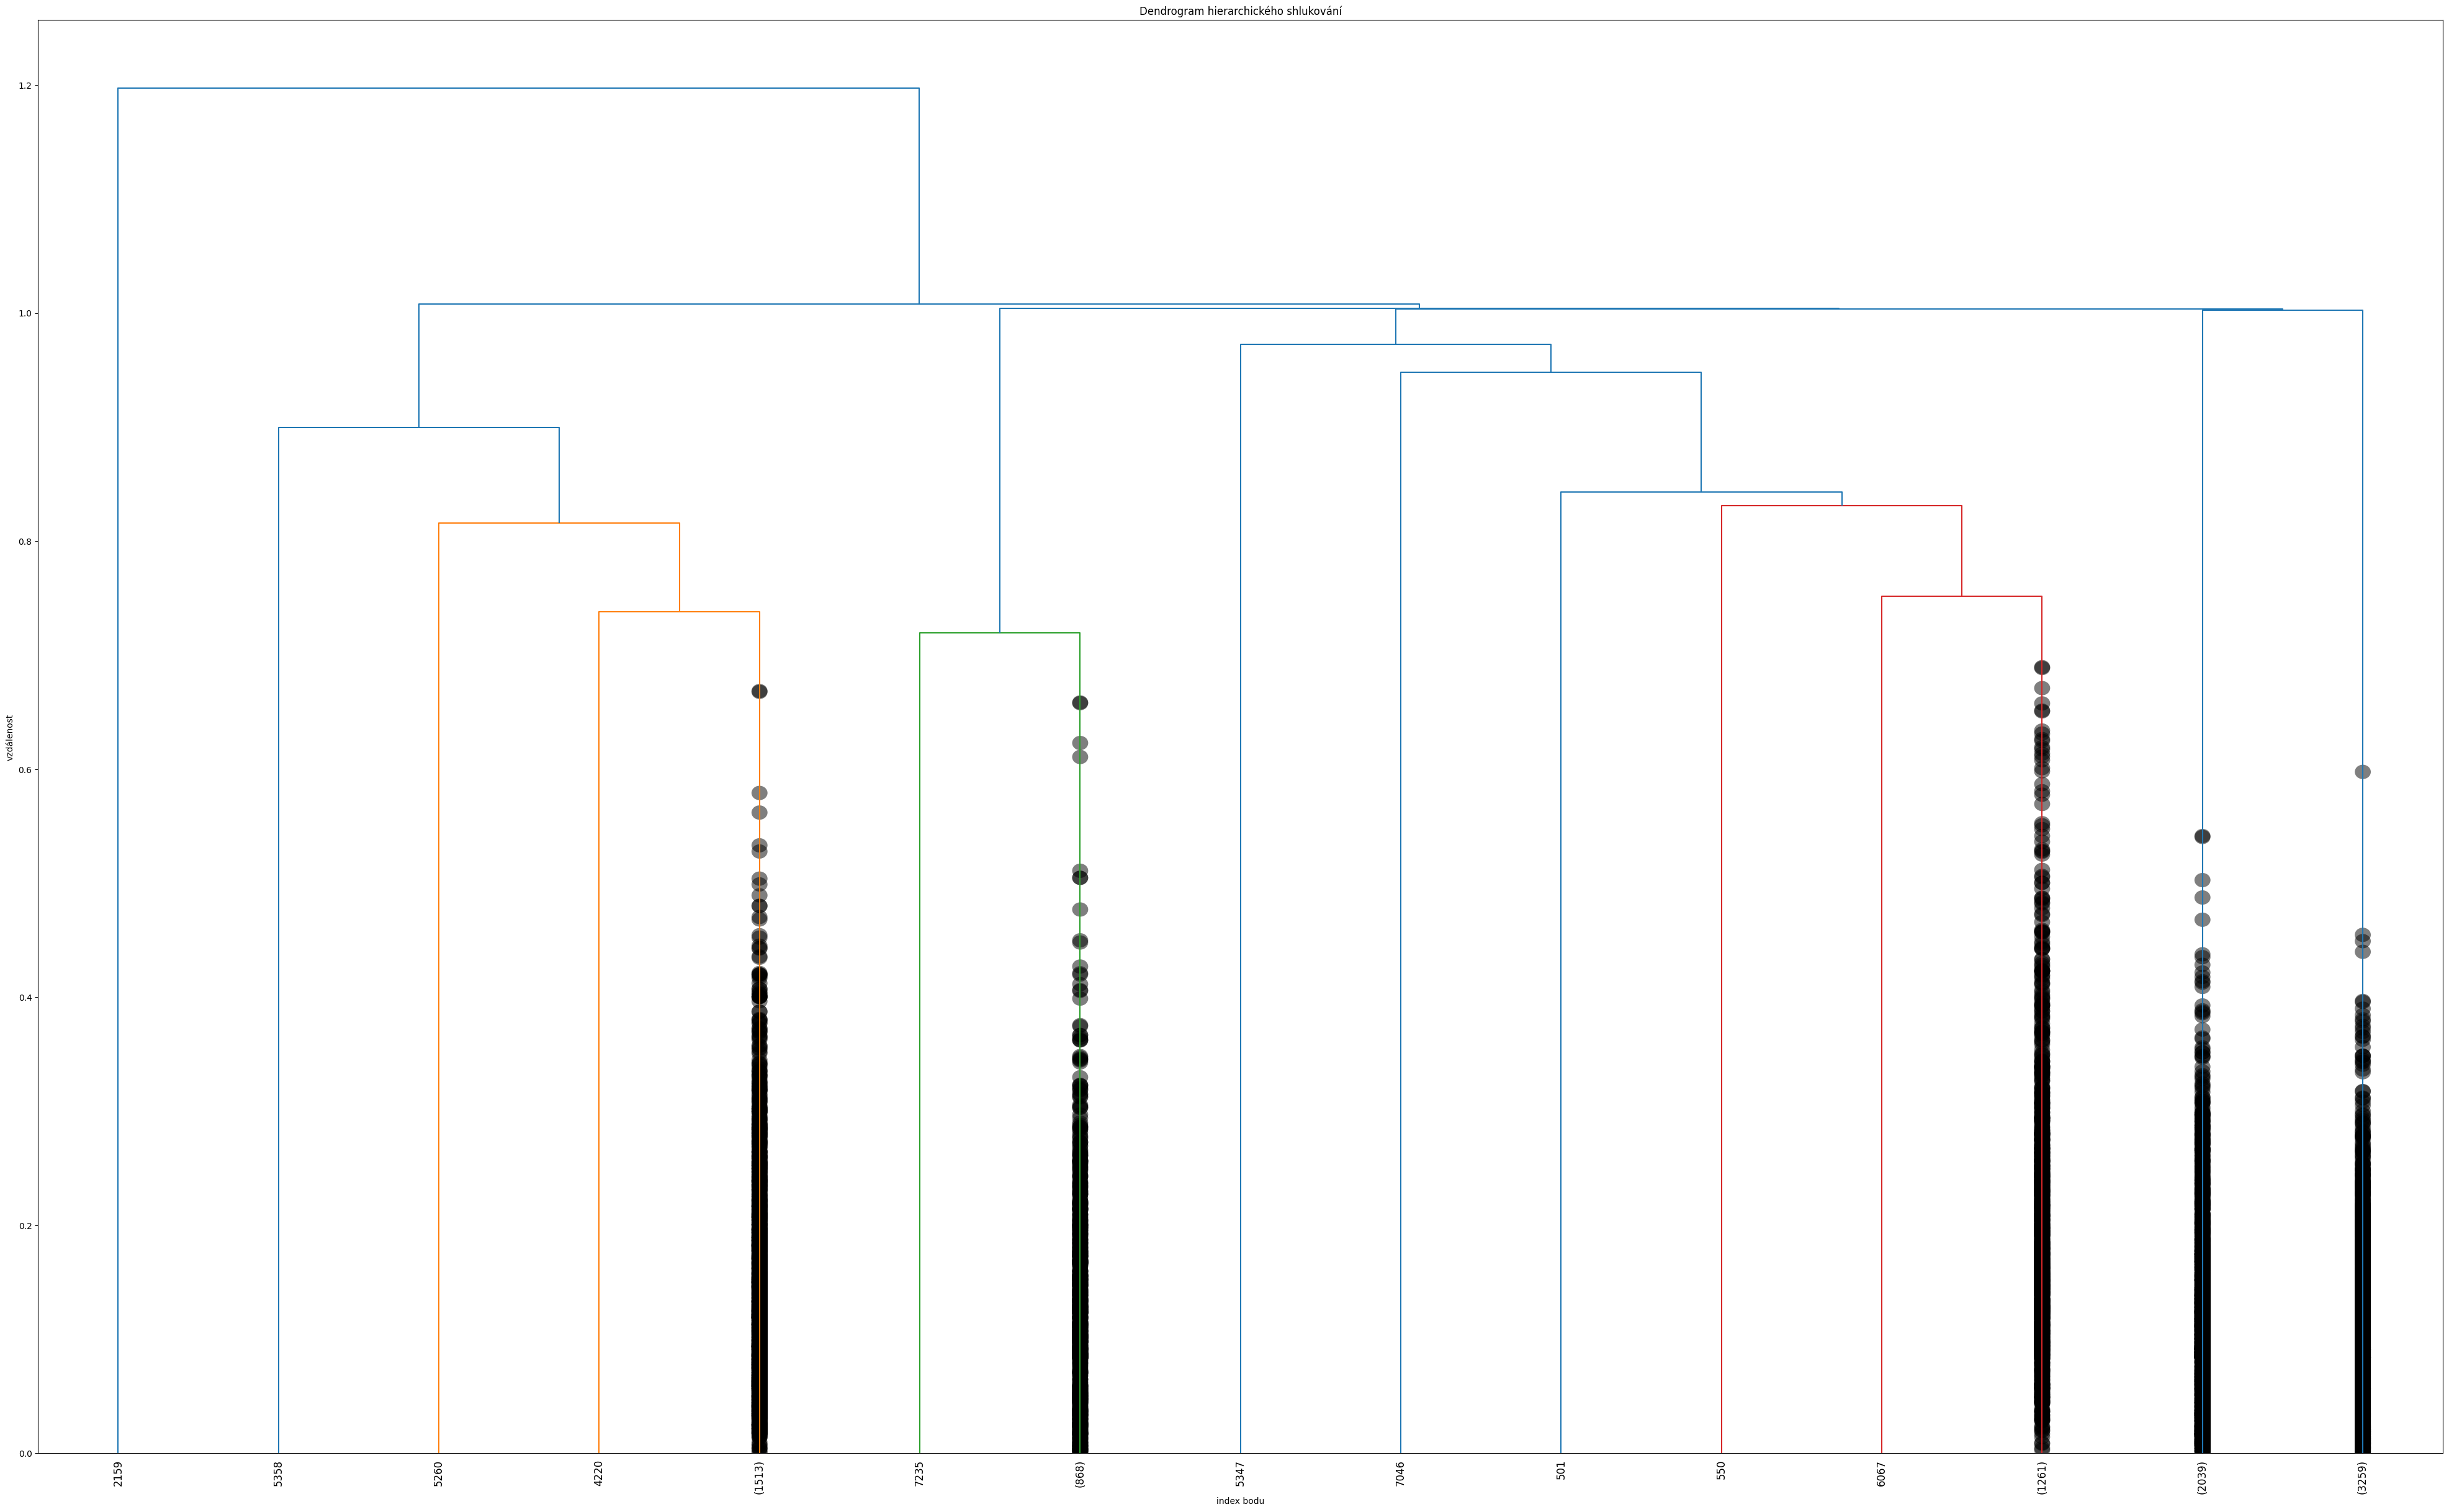

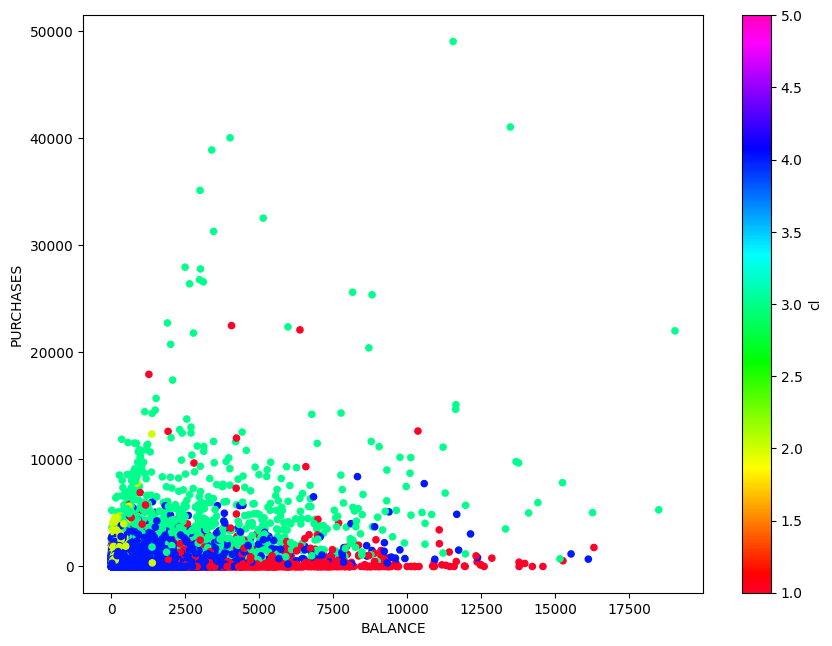

Method used: complete
The silhouette score is 0.543


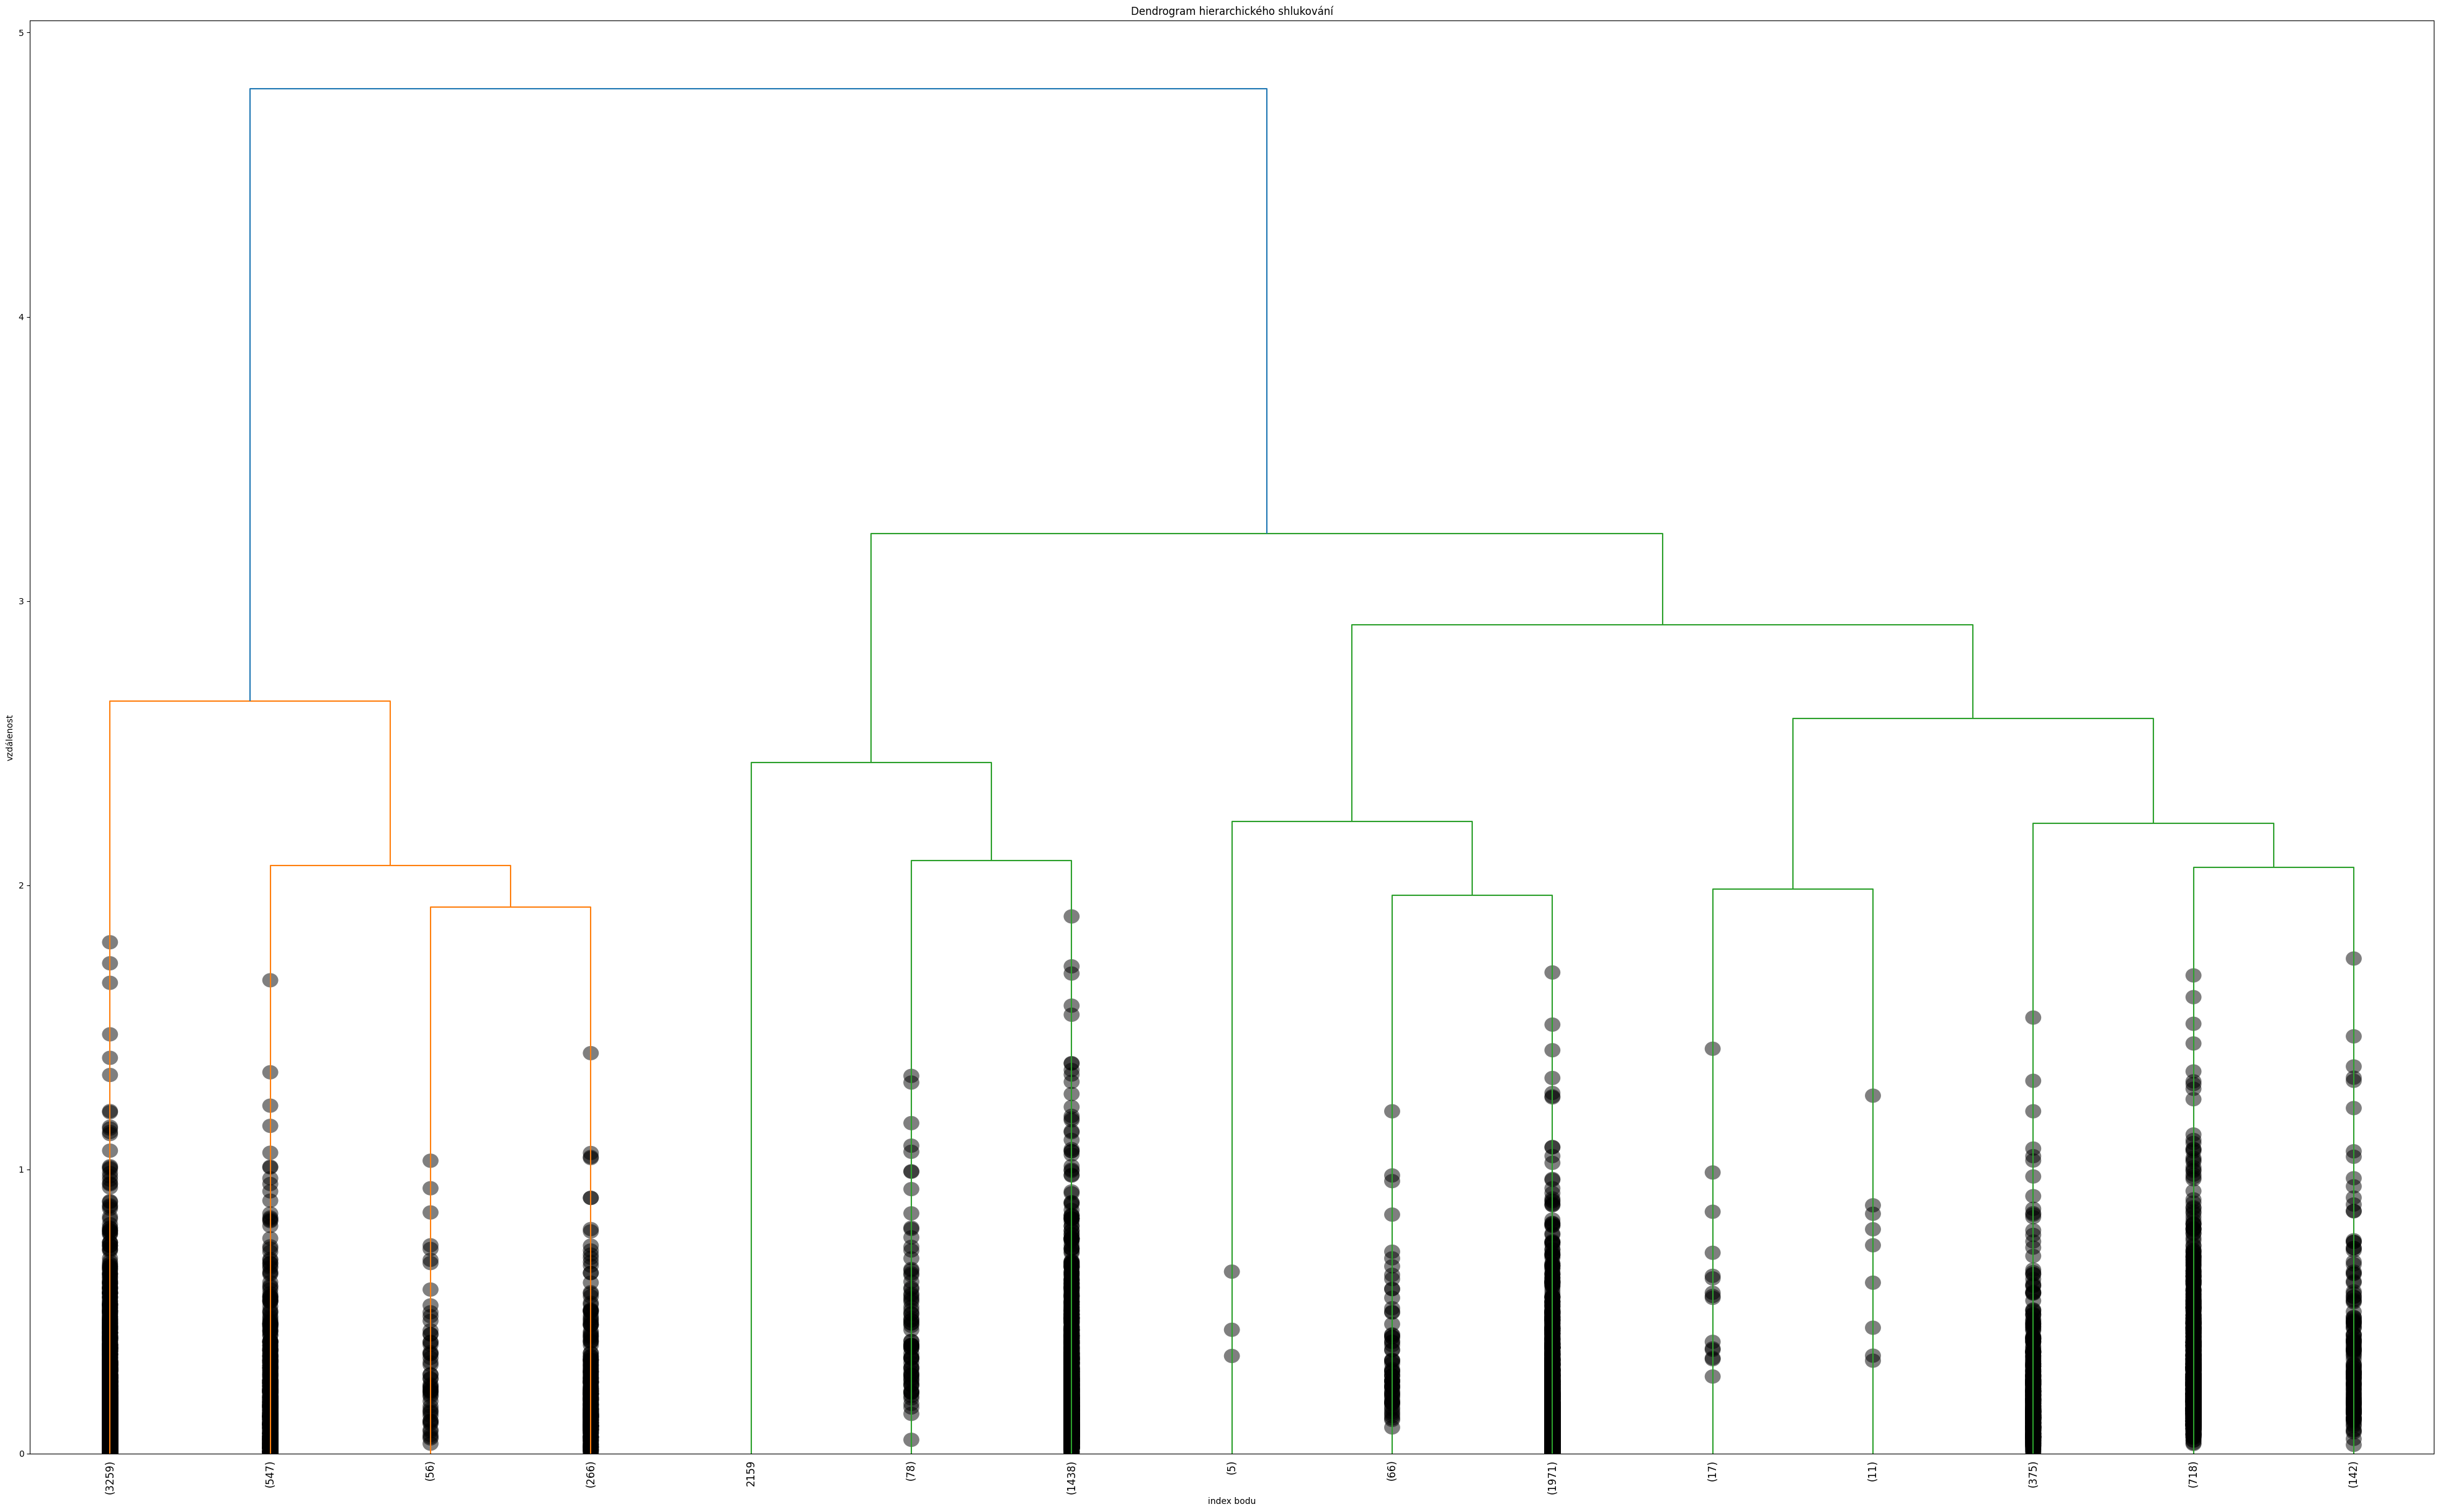

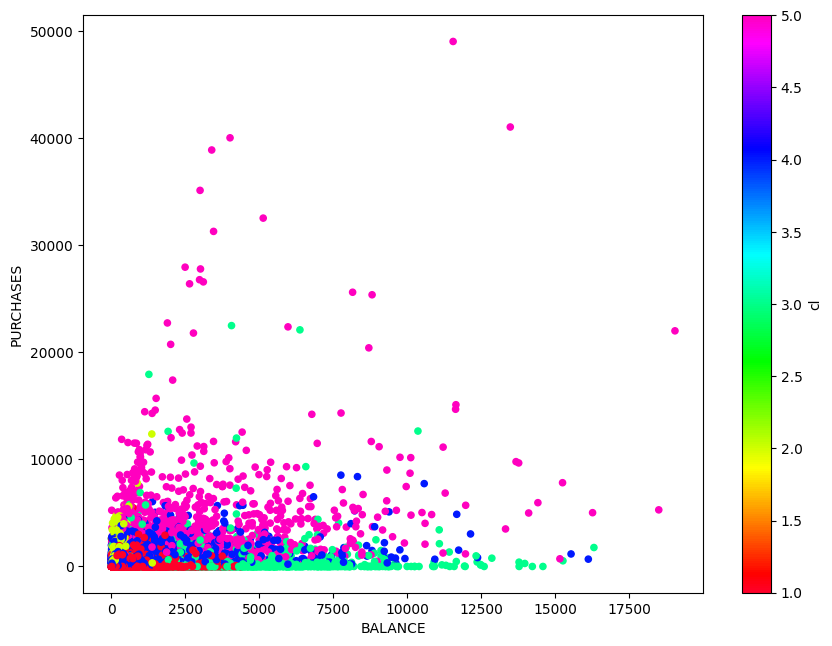

Method used: average
The silhouette score is 0.493


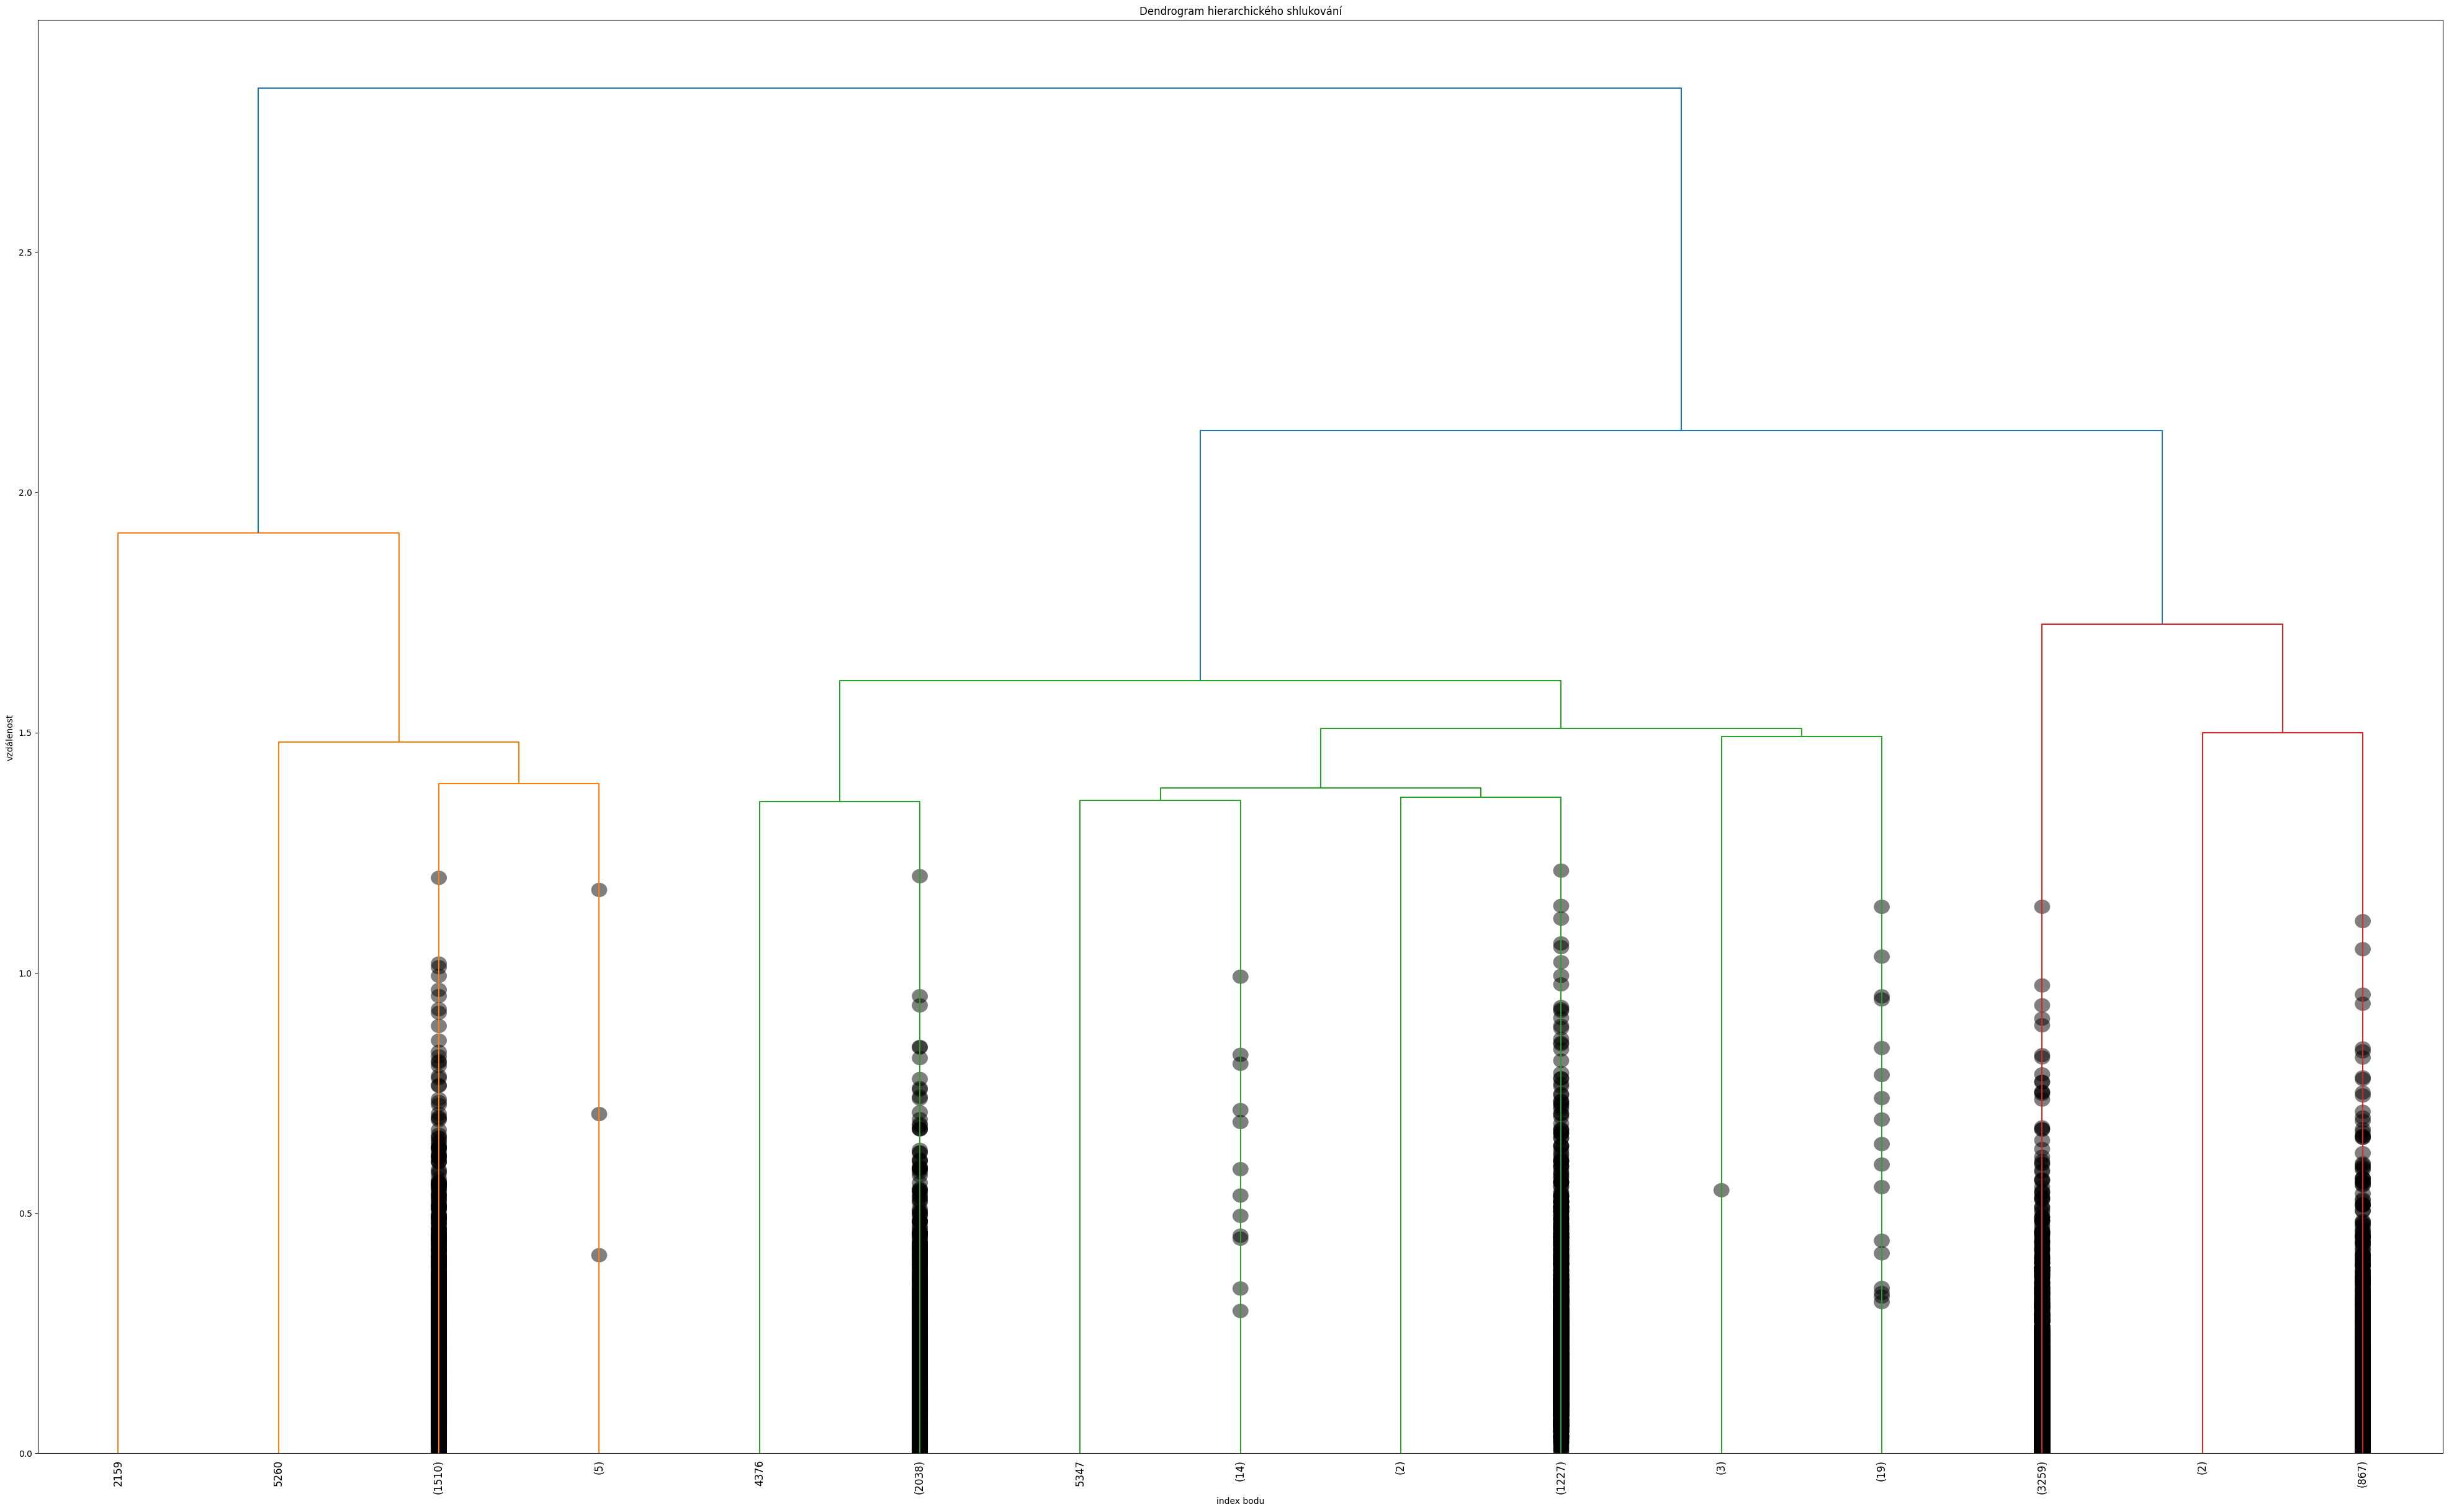

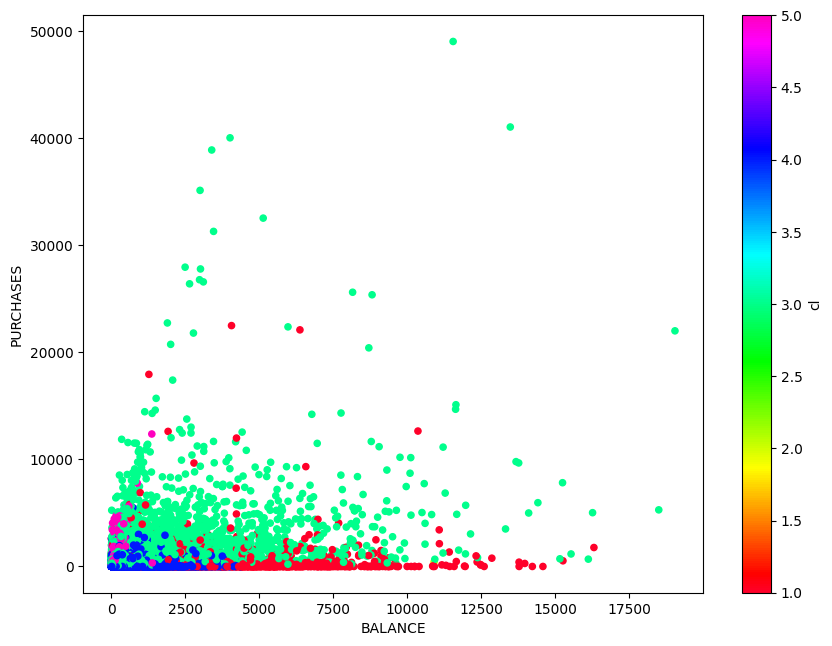

In [21]:
methods = ["ward", "single", "complete", "average"]

for i in methods:
    Z = linkage(df_normalized, method=i, metric="euclidean")
    k_clusters = fcluster(Z, 5, criterion="maxclust")
    score = silhouette_score(df_normalized, k_clusters)
    print("Method used: " + i)
    print(f"The silhouette score is {score:.3f}")
    plt.figure(figsize=(50, 30))
    plt.title("Dendrogram hierarchického shlukování")
    plt.xlabel("index bodu")
    plt.ylabel("vzdálenost")
    dendrogram(Z, truncate_mode='lastp', p=15, leaf_rotation=90, leaf_font_size=12, show_contracted=True)


    plt.show()
    BalancePurchasesGraph(k_clusters, dfdata)

Looking at all the graphs, ward method has achieved the best silhouette score while also splitting the data points at least a little sensibly in the balance/purchase_frequency graph.

From the dendogram we can see a large distance gap between 5 and 6 clusters, suggesting that 5 might be the ideal number of clusters. 

<b>Results</b>

Two best models when looking at silhouette scores and ideal number of clusters seem to be normalized kmeans with 5 clusters and ward hierarchical clustering also with 5 clusters.
(Though graphs using standardization do look the best, but the low silhouette score suggests it's just very skewed in one direction.)

The best one will be picked by visually comparing if they separated the credit card holders in a suitable way for us. That means the best split between people with low and high balance aswell as people with low and high purchasing frequency habits. 
As an extra criterium we will compare credit card limits and the largest one off purchase to determine if people willing to spend a lot of money in one go are in the same cluster.

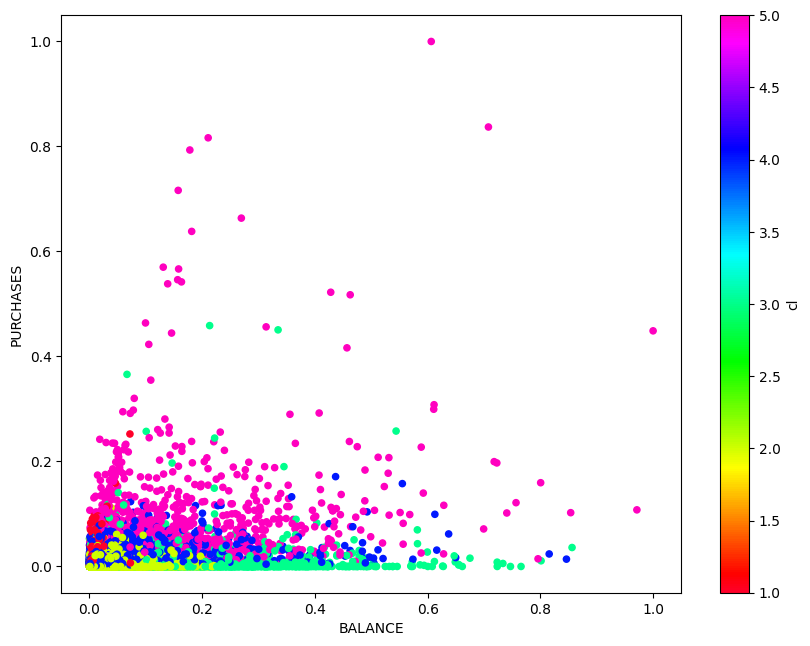

The silhouette score is 0.493


<AxesSubplot: xlabel='BALANCE', ylabel='ONEOFF_PURCHASES'>

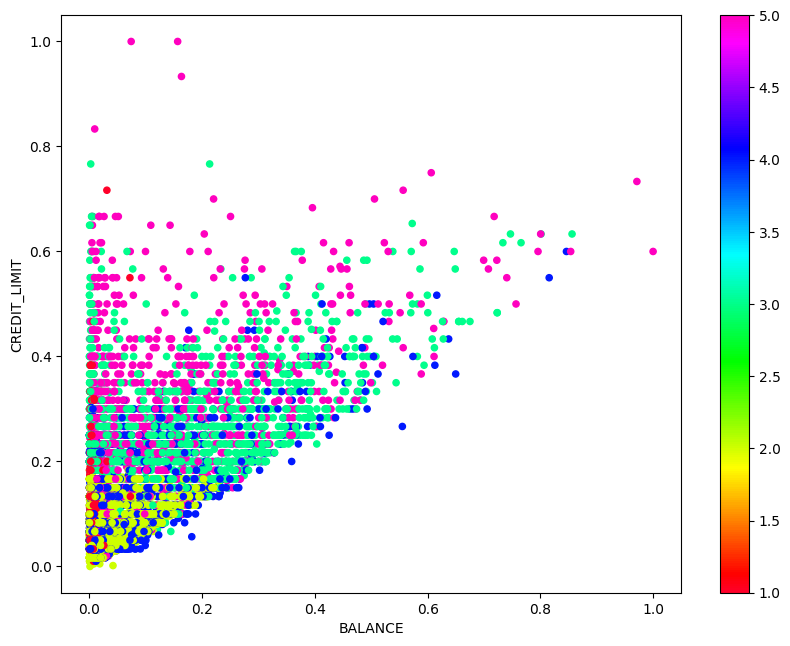

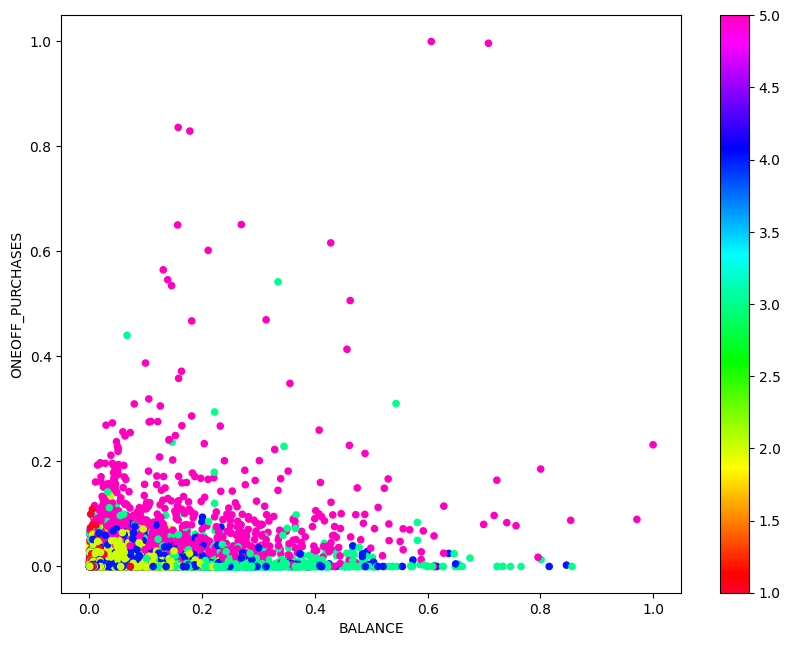

In [22]:
Z = linkage(df_normalized, method="ward", metric="euclidean")
k_clusters = fcluster(Z, 5, criterion="maxclust")
BalancePurchasesGraph(k_clusters, df_normalized)
score = silhouette_score(df_normalized, k_clusters)
print(f"The silhouette score is {score:.3f}")
df_normalized.plot.scatter('BALANCE', 'CREDIT_LIMIT', c=k_clusters, colormap='gist_rainbow')
df_normalized.plot.scatter('BALANCE', 'ONEOFF_PURCHASES', c=k_clusters, colormap='gist_rainbow')

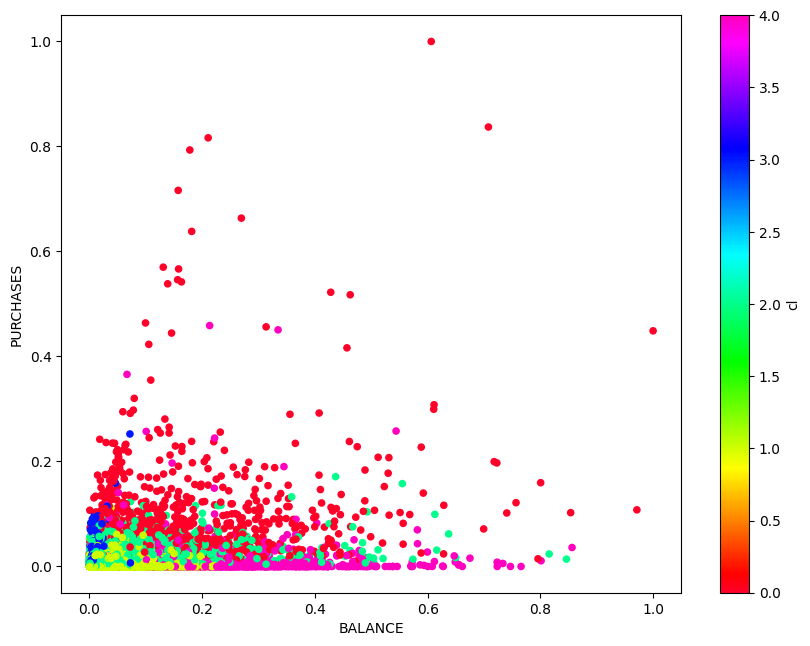

The silhouette score is 0.546


<AxesSubplot: xlabel='BALANCE', ylabel='ONEOFF_PURCHASES'>

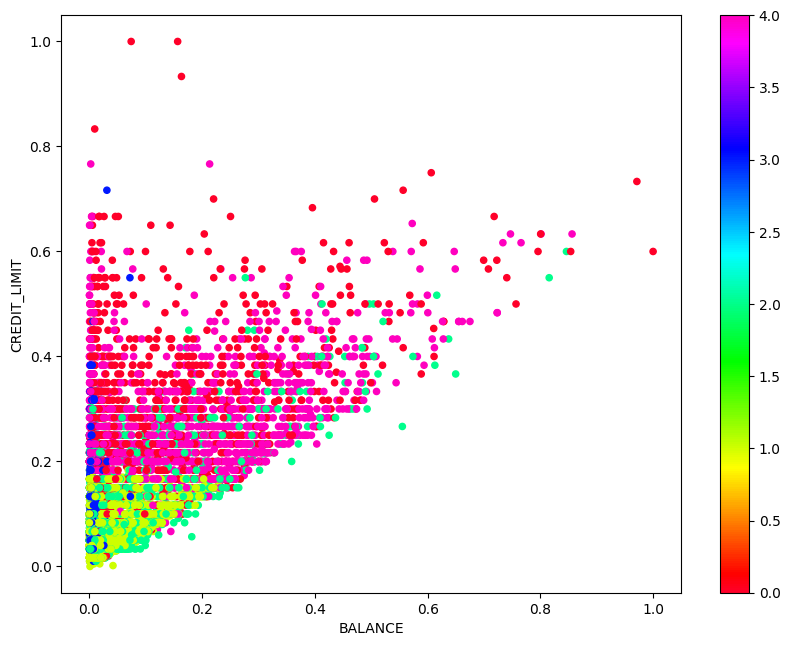

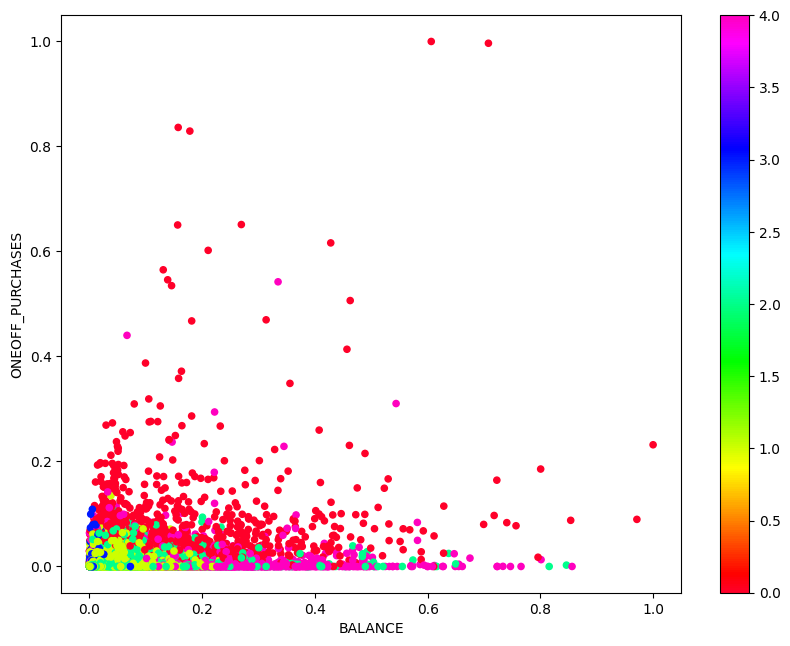

In [23]:
kmeans = KMeans(n_clusters = 5, random_state= 1).fit(df_normalized)
BalancePurchasesGraph(kmeans.labels_, df_normalized)
score = silhouette_score(df_normalized, kmeans.labels_)
print(f"The silhouette score is {score:.3f}")
df_normalized.plot.scatter('BALANCE', 'CREDIT_LIMIT', c=kmeans.labels_, colormap='gist_rainbow')
df_normalized.plot.scatter('BALANCE', 'ONEOFF_PURCHASES', c=kmeans.labels_, colormap='gist_rainbow')

The normalized kmeans did separate the points a little bit better.
It is still very hard to see anything useful from the graphs as there are a lot more than 2 features/dimensions in the dataset and this time we want to base the clutering off of all the variables avaliable.
 
In the balance/purchasing graph we can see clusters of people with low balance split in by their purchasing habits, another two clusters of people with higher balance but lower number of purchases and a large cluster with everyone else.

The balance/credit_limit graph puts some clusters in the range of low credit limtis and low balance, while the other group of clusters is clearly separated in the higher ranges. 

In the balance/oneoff_purchases we see that many people with expensive purchases seem to be in a separate cluster. While the rest is divided mostly by their balance.

Reducing number of dimensions either through algorithms or throwing out some columns would likely produce nicer graphs to look at.

Important note: I am still not sure if the assignment was to run clustering on the whole dataset, choose the best one and interpret created clusters. 
Or if it was to choose some columns and try to create clusters based on some criteria we chose beforehand.
Remarkably it runs quite well even if it's done in the latter way, just uncomment the df line near the top which drops all other columns, obviously the text now won't match the results precisely.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=dfa22fe5-d21e-4327-9a0a-b1ea3b60625f' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>